In [1]:
print("Hello, Google Colab!")

Hello, Google Colab!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving hypertension_dataset (1).csv to hypertension_dataset (1).csv


In [3]:

import pandas as pd

df = pd.read_csv("hypertension_dataset (1).csv")

df.head()


,Age,Salt_Intake,Stress_Score,BP_History,Sleep_Duration,BMI,Medication,Family_History,Exercise_Level,Smoking_Status,Has_Hypertension
0,69,8.0,9,Normal,6.4,25.8,NaN,Yes,Low,Non-Smoker,Yes
1,32,11.7,10,Normal,5.4,23.4,NaN,No,Low,Non-Smoker,No
2,78,9.5,3,Normal,7.1,18.7,NaN,No,Moderate,Non-Smoker,No
3,38,10.0,10,Hypertension,4.2,22.1,ACE Inhibitor,No,Low,Non-Smoker,Yes
4,41,9.8,1,Prehypertension,5.8,16.2,Other,No,Moderate,Non-Smoker,No


In [4]:
df.shape

(1985, 11)

In [5]:
df.columns

Index(['Age', 'Salt_Intake', 'Stress_Score', 'BP_History', 'Sleep_Duration',
       'BMI', 'Medication', 'Family_History', 'Exercise_Level',
       'Smoking_Status', 'Has_Hypertension'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1985 entries, 0 to 1984
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Age               1985 non-null   int64  
 1   Salt_Intake       1985 non-null   float64
 2   Stress_Score      1985 non-null   int64  
 3   BP_History        1985 non-null   object 
 4   Sleep_Duration    1985 non-null   float64
 5   BMI               1985 non-null   float64
 6   Medication        1186 non-null   object 
 7   Family_History    1985 non-null   object 
 8   Exercise_Level    1985 non-null   object 
 9   Smoking_Status    1985 non-null   object 
 10  Has_Hypertension  1985 non-null   object 
dtypes: float64(3), int64(2), object(6)
memory usage: 170.7+ KB


In [7]:
df.describe()

,Age,Salt_Intake,Stress_Score,Sleep_Duration,BMI
count,1985.000000,1985.000000,1985.000000,1985.000000,1985.000000
mean,50.341058,8.531688,4.979345,6.452242,26.015315
std,19.442042,1.994907,3.142303,1.542207,4.512857
min,18.000000,2.500000,0.000000,1.500000,11.900000
25%,34.000000,7.200000,2.000000,5.400000,23.000000
50%,50.000000,8.500000,5.000000,6.500000,25.900000
75%,67.000000,9.900000,8.000000,7.500000,29.100000
max,84.000000,16.400000,10.000000,11.400000,41.900000


In [8]:
df.count()


,0
Age,1985
Salt_Intake,1985
Stress_Score,1985
BP_History,1985
Sleep_Duration,1985
BMI,1985
Medication,1186
Family_History,1985
Exercise_Level,1985
Smoking_Status,1985


In [9]:
df.isnull().sum()

,0
Age,0
Salt_Intake,0
Stress_Score,0
BP_History,0
Sleep_Duration,0
BMI,0
Medication,799
Family_History,0
Exercise_Level,0
Smoking_Status,0


In [10]:

# Check Missing Values

print("Missing Values:")
print(df.isnull().sum())

# Check Duplicate Rows

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
Age                   0
Salt_Intake           0
Stress_Score          0
BP_History            0
Sleep_Duration        0
BMI                   0
Medication          799
Family_History        0
Exercise_Level        0
Smoking_Status        0
Has_Hypertension      0
dtype: int64

Duplicate Rows:
0


In [11]:

# Check unique values of categorical columns

categorical_columns = [
    'BP_History',
    'Medication',
    'Family_History',
    'Exercise_Level',
    'Smoking_Status',
    'Has_Hypertension'
]

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False))

print(pd.crosstab(df['BP_History'], df['Has_Hypertension']))



 BP_History
BP_History
Normal             796
Prehypertension    620
Hypertension       569
Name: count, dtype: int64

 Medication
Medication
NaN              799
Beta Blocker     412
ACE Inhibitor    323
Diuretic         245
Other            206
Name: count, dtype: int64

 Family_History
Family_History
No     1000
Yes     985
Name: count, dtype: int64

 Exercise_Level
Exercise_Level
Low         936
Moderate    658
High        391
Name: count, dtype: int64

 Smoking_Status
Smoking_Status
Non-Smoker    1417
Smoker         568
Name: count, dtype: int64

 Has_Hypertension
Has_Hypertension
Yes    1032
No      953
Name: count, dtype: int64
Has_Hypertension   No  Yes
BP_History                
Hypertension       41  528
Normal            510  286
Prehypertension   402  218


In [12]:

# Create a copy of the original dataset

df_model = df.copy()

# Drop Medication column

df_model = df_model.drop(columns=['Medication'])

# Check dataset shape

print("Original Dataset Shape:", df.shape)

print("New Dataset Shape:", df_model.shape)

# Check missing values again

print("\nMissing Values:")
print(df_model.isnull().sum())


Original Dataset Shape: (1985, 11)
New Dataset Shape: (1985, 10)

Missing Values:
Age                 0
Salt_Intake         0
Stress_Score        0
BP_History          0
Sleep_Duration      0
BMI                 0
Family_History      0
Exercise_Level      0
Smoking_Status      0
Has_Hypertension    0
dtype: int64


In [13]:

# Identify Numerical Columns

numerical_columns = df_model.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify Categorical Columns

categorical_columns = df_model.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['Age', 'Salt_Intake', 'Stress_Score', 'Sleep_Duration', 'BMI']

Categorical Columns:
['BP_History', 'Family_History', 'Exercise_Level', 'Smoking_Status', 'Has_Hypertension']


In [14]:

# Separate Features (X) and Target (y)

X = df_model.drop(columns=['Has_Hypertension'])

y = df_model['Has_Hypertension']

# Check shapes

print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

print("\nTarget Values:")
print(y.unique())


Features Shape: (1985, 9)
Target Shape: (1985,)

Feature Columns:
['Age', 'Salt_Intake', 'Stress_Score', 'BP_History', 'Sleep_Duration', 'BMI', 'Family_History', 'Exercise_Level', 'Smoking_Status']

Target Values:
['Yes' 'No']


In [15]:

from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the shapes

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (1588, 9)
X_test: (397, 9)
y_train: (1588,)
y_test: (397,)


In [16]:

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Identify numerical and categorical features

num_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

cat_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

# Create preprocessing system

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ]
)

# Fit on training data and transform

X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data

X_test_processed = preprocessor.transform(X_test)

# Check results

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)


Training Data Shape: (1588, 15)
Testing Data Shape: (397, 15)


In [17]:

# Import KNN Classifier

from sklearn.neighbors import KNeighborsClassifier

# Create KNN Model

knn = KNeighborsClassifier(n_neighbors=5)

# Train the Model

knn.fit(X_train_processed, y_train)

print("KNN Model Training Completed!")


KNN Model Training Completed!


In [18]:

# Predict using Testing Data

y_pred = knn.predict(X_test_processed)

print("Predictions:")
print(y_pred[:20])


Predictions:
['Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No'
 'No' 'Yes' 'No' 'No' 'No' 'Yes' 'No']


In [19]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 84.63476070528966 %


In [20]:

from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Confusion Matrix:
[[175  16]
 [ 45 161]]

Classification Report:
              precision    recall  f1-score   support

          No       0.80      0.92      0.85       191
         Yes       0.91      0.78      0.84       206

    accuracy                           0.85       397
   macro avg       0.85      0.85      0.85       397
weighted avg       0.85      0.85      0.85       397



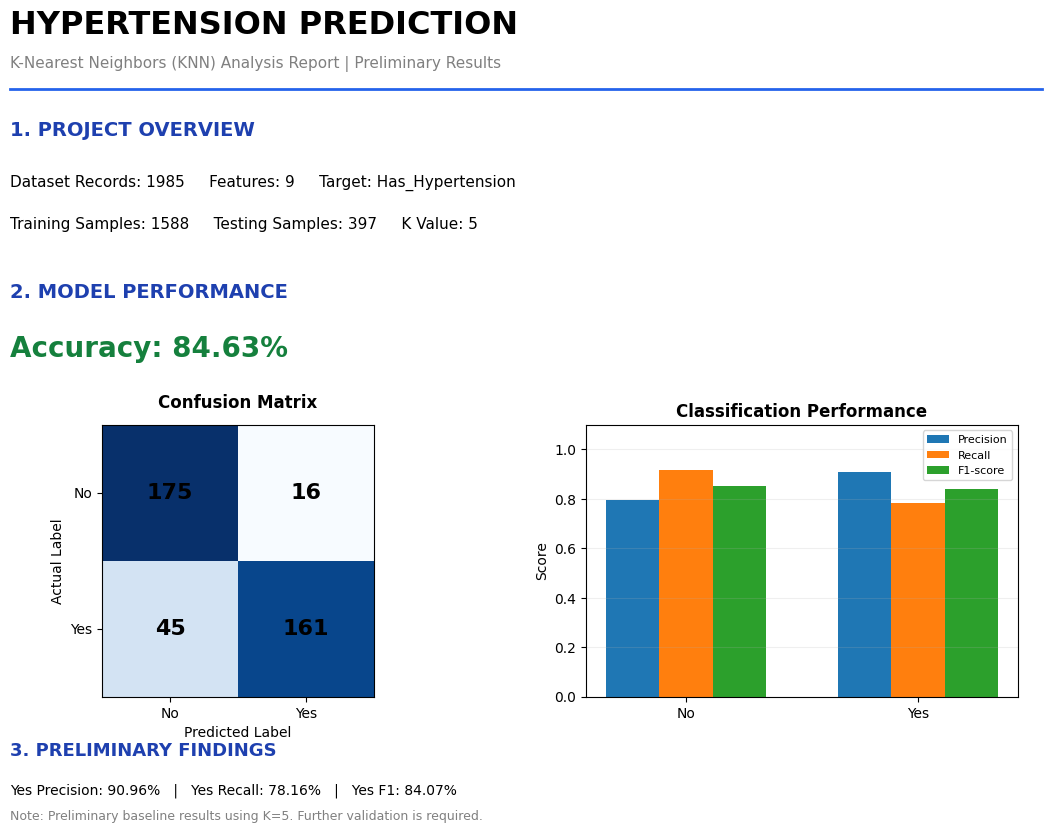

In [21]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# Calculate evaluation metrics
labels = ['No', 'Yes']

cm = confusion_matrix(y_test, y_pred, labels=labels)

report = classification_report(
    y_test,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)

accuracy = accuracy_score(y_test, y_pred)

# Create Report
fig = plt.figure(figsize=(12, 8.5), facecolor='white')

fig.text(
    0.07, 0.95,
    'HYPERTENSION PREDICTION',
    fontsize=23, fontweight='bold'
)

fig.text(
    0.07, 0.91,
    'K-Nearest Neighbors (KNN) Analysis Report | Preliminary Results',
    fontsize=11, color='gray'
)

fig.add_artist(plt.Line2D(
    [0.07, 0.93], [0.885, 0.885],
    color='#2563EB', linewidth=2
))

# Project Overview
fig.text(0.07, 0.83, '1. PROJECT OVERVIEW',
         fontsize=14, fontweight='bold', color='#1E40AF')

fig.text(
    0.07, 0.77,
    f'Dataset Records: {len(df_model)}'
    f'     Features: {X.shape[1]}'
    f'     Target: Has_Hypertension',
    fontsize=11
)

fig.text(
    0.07, 0.72,
    f'Training Samples: {len(X_train)}'
    f'     Testing Samples: {len(X_test)}'
    f'     K Value: 5',
    fontsize=11
)

# Accuracy
fig.text(0.07, 0.64, '2. MODEL PERFORMANCE',
         fontsize=14, fontweight='bold', color='#1E40AF')

fig.text(
    0.07, 0.57,
    f'Accuracy: {accuracy * 100:.2f}%',
    fontsize=20, fontweight='bold', color='#15803D'
)

# Confusion Matrix
ax1 = fig.add_axes([0.08, 0.17, 0.36, 0.32])

ax1.imshow(cm, cmap='Blues')

ax1.set_title('Confusion Matrix', fontweight='bold', pad=12)
ax1.set_xlabel('Predicted Label')
ax1.set_ylabel('Actual Label')

ax1.set_xticks([0, 1])
ax1.set_xticklabels(labels)
ax1.set_yticks([0, 1])
ax1.set_yticklabels(labels)

for i in range(2):
    for j in range(2):
        ax1.text(
            j, i, str(cm[i, j]),
            ha='center', va='center',
            fontsize=16, fontweight='bold',
            color='black'
        )

# Classification Metrics
ax2 = fig.add_axes([0.55, 0.17, 0.36, 0.32])

classes = ['No', 'Yes']
metrics = ['precision', 'recall', 'f1-score']

x = np.arange(2)
width = 0.23

for i, metric in enumerate(metrics):
    values = [report[c][metric] for c in classes]

    ax2.bar(
        x + (i - 1) * width,
        values,
        width,
        label=metric.capitalize()
    )

ax2.set_title('Classification Performance', fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(classes)
ax2.set_ylim(0, 1.1)
ax2.set_ylabel('Score')
ax2.legend(fontsize=8)
ax2.grid(axis='y', alpha=0.2)

# Conclusion
fig.text(0.07, 0.10, '3. PRELIMINARY FINDINGS',
         fontsize=13, fontweight='bold', color='#1E40AF')

fig.text(
    0.07, 0.055,
    f"Yes Precision: {report['Yes']['precision']*100:.2f}%"
    f"   |   Yes Recall: {report['Yes']['recall']*100:.2f}%"
    f"   |   Yes F1: {report['Yes']['f1-score']*100:.2f}%",
    fontsize=10
)

fig.text(
    0.07, 0.025,
    'Note: Preliminary baseline results using K=5. Further validation is required.',
    fontsize=9, color='gray'
)

# Save PDF
plt.savefig(
    'Hypertension_KNN_Analysis_Report.pdf',
    format='pdf',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [22]:
from google.colab import files

files.download('Hypertension_KNN_Analysis_Report.pdf')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# Hypertension Prediction Using KNN

**Project Type:** Supervised Machine Learning

**Algorithm:** K-Nearest Neighbors (KNN)

**Problem Type:** Binary Classification

**Target:** Has_Hypertension (Yes / No)

## Project Workflow

### Phase 1: Data Collection & Understanding
1. Dataset Upload
2. Import Libraries
3. Load Dataset using Pandas
4. Exploratory Data Analysis (EDA)
5. Missing Values Analysis
6. Duplicate Checking
7. Categorical Data Analysis

### Phase 2: Data Preprocessing
8. Create Working Dataset
9. Handle Missing Values
10. Feature Identification
11. Separate Features (X) and Target (y)
12. Train-Test Split (80:20)
13. Categorical Encoding (OneHotEncoder)
14. Feature Scaling (StandardScaler)

### Phase 3: Model Development
15. Import KNN Classifier
16. Create KNN Model (K=5)
17. Train the Model
18. Predict Testing Data

### Phase 4: Model Evaluation
19. Accuracy Score
20. Confusion Matrix
21. Precision
22. Recall
23. F1-Score

### Phase 5: Remaining Work
24. Best K Selection
25. Data Leakage Investigation
26. Model Comparison
27. Final Model Selection
28. Final Evaluation
29. Visualization & PDF Report
